# Stats 161 Midterm Project

## Data import

We select **12 consecutive weeks of Polymarket data, from June 1 to August 23, 2026**, to study wallet trading behavior. All dates and timestamps use UTC.


### 1. Setup


In [8]:
import os
from getpass import getpass

import pandas as pd
import requests

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from io import BytesIO


In [53]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
clean_trades = pd.read_parquet("clean_trades.parquet")
markets = pd.read_pickle("markets.pkl"); events = pd.read_pickle("events.pkl"); resolutions = pd.read_pickle("resolutions.pkl")

### 2. Dates and access settings


In [13]:
start_date = "2026-06-01"
end_date = "2026-08-23"
dates = pd.date_range(start_date, end_date, freq="D", tz="UTC")

base_url = "https://d1yyqbluk0oz0t.cloudfront.net"
course_password = os.environ.get("POLYMARKET_PASSWORD") or getpass("Course password: ")
# PolymarketData2026!


### 3. Wallet trades

We combine the 84 daily trade files into `wallet_trades`, keeping all wallets and all eight original variables. Each row is a recorded fill; one order may produce multiple fills.

| Variable | Description |
|---|---|
| `wallet` | Pseudonymous wallet ID, consistent across daily files. |
| `market` | Market slug; links to `markets.slug`. |
| `time` | Fill timestamp in UTC. |
| `side` | BUY or SELL for the recorded wallet. |
| `outcome` | Traded outcome, such as Yes, No, Up, Down, or a team name. |
| `price` | Execution price per share. |
| `size` | Number of shares traded. |
| `dollars` | Recorded dollar value of the fill. |


In [14]:
session = requests.Session()
session.auth = ("polymarketdatabase", course_password)
daily_trades = []

for day in dates:
    date_string = day.strftime("%Y-%m-%d")
    url = f"{base_url}/wallet_trades/trades-{date_string}.parquet"

    response = session.get(url, timeout=120)
    response.raise_for_status()
    day_trades = pd.read_parquet(BytesIO(response.content), dtype_backend="pyarrow")
    day_trades["time"] = pd.to_datetime(day_trades["time"], utc=True)

    # Check the file date.
    assert len(day_trades) > 0, f"Empty file: {date_string}"
    assert day_trades["time"].min().date() == day.date(), f"Unexpected date: {date_string}"
    assert day_trades["time"].max().date() == day.date(), f"Unexpected date: {date_string}"

    daily_trades.append(day_trades)
    if len(daily_trades) % 28 == 0:
        print(f"Loaded {len(daily_trades)} of {len(dates)} daily files.")

wallet_trades = pd.concat(daily_trades, ignore_index=True)
session.close()
del daily_trades, day_trades, response

print(f"Wallet trades imported: {len(wallet_trades):,} rows.")


Loaded 28 of 84 daily files.
Loaded 56 of 84 daily files.
Loaded 84 of 84 daily files.
Wallet trades imported: 66,736,398 rows.


### 4. Related market data

We import market, event, and settlement records for the markets in `wallet_trades`. All original columns are retained; key variables are listed below.

| DataFrame | Content | Key variables |
|---|---|---|
| `markets` | Market questions, outcome labels, and parent events. | `slug`, `title`, `event_slug`, `condition_id`, `outcomes`, `token_ids`, `start_date`, `end_date` |
| `events` | Event titles, descriptions, and scheduled dates. | `slug`, `title`, `description`, `start_date`, `end_date` |
| `resolutions` | Available settlement records. | `market_slug`, `resolved_yes`, `price_at_close`, `resolved_at` |

**Links:** `wallet_trades.market` → `markets.slug`; `markets.event_slug` → `events.slug`; `resolutions.market_slug` → `markets.slug`.

Market prices and volumes in the metadata reflect the current stored snapshot. Interpret resolution labels using the market's actual outcome labels.


In [15]:
database_url = URL.create(
    "postgresql+psycopg2",
    username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
    password=course_password,
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres",
)

engine = create_engine(
    database_url,
    connect_args={"sslmode": "require", "connect_timeout": 20},
    execution_options={"postgresql_readonly": True},
)

market_slugs = wallet_trades["market"].dropna().unique().tolist()

with engine.connect() as connection:
    markets = pd.read_sql_query(
        text("SELECT * FROM public.markets WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )
    resolutions = pd.read_sql_query(
        text("SELECT * FROM public.resolutions WHERE market_slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )


In [17]:
event_slugs = markets["event_slug"].dropna().unique().tolist()

with engine.connect() as connection:
    events = pd.read_sql_query(
        text("SELECT * FROM public.events WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": event_slugs},
    )

engine.dispose()


### 5. Import check

Confirm the row and column counts, and report traded markets without matching catalog metadata.


In [18]:
for name, data in [("wallet_trades", wallet_trades), ("markets", markets),
                   ("events", events), ("resolutions", resolutions)]:
    print(f"{name}: {len(data):,} rows, {len(data.columns)} columns")

missing_market_slugs = set(market_slugs) - set(markets["slug"])
print(f"Traded market slugs without catalog metadata: {len(missing_market_slugs):,}")
print(f"Study period: {start_date} through {end_date} (UTC)")


wallet_trades: 66,736,398 rows, 8 columns
markets: 227,655 rows, 25 columns
events: 98,132 rows, 13 columns
resolutions: 42,966 rows, 6 columns
Traded market slugs without catalog metadata: 119
Study period: 2026-06-01 through 2026-08-23 (UTC)


## Data Cleaning

### 1. Check data quality

Check missing values, trade fields, recorded amounts (tolerance: $0.01), repeated rows, and market links. Counts can overlap.


In [20]:
missing_values = wallet_trades.isna().any(axis=1)
invalid_side = ~wallet_trades["side"].isin(["BUY", "SELL"])
invalid_price = ~wallet_trades["price"].between(0, 1)
negative_size = wallet_trades["size"] < 0
negative_dollars = wallet_trades["dollars"] < 0
amount_mismatch = (
    wallet_trades["dollars"] - wallet_trades["price"] * wallet_trades["size"]
).abs() > 0.01
repeated_rows = wallet_trades.duplicated()
missing_metadata = ~wallet_trades["market"].isin(markets["slug"])

quality_check = pd.Series({
    "Missing values in any trade column": missing_values.sum(),
    "Side outside BUY / SELL": invalid_side.sum(),
    "Price outside [0, 1]": invalid_price.sum(),
    "Negative shares": negative_size.sum(),
    "Negative dollar value": negative_dollars.sum(),
    "Dollar difference above $0.01": amount_mismatch.sum(),
    "Repeated rows after the first": repeated_rows.sum(),
    "Trades without market metadata": missing_metadata.sum(),
}, name="Rows").to_frame()

quality_check


,Rows
Missing values in any trade column,0
Side outside BUY / SELL,0
"Price outside [0, 1]",0
Negative shares,0
Negative dollar value,0
Dollar difference above $0.01,0
Repeated rows after the first,2509300
Trades without market metadata,147668


### 2. Prepare the analysis data

Use `clean_trades` for the next analysis steps.

The checks found no missing or invalid trade values, so no rows need to be removed.

Repeated rows are kept because identical records cannot be confirmed as duplicates without a trade ID. Trades without market metadata are also kept. `has_market_metadata` indicates whether a trade's `market` matches `markets.slug`.

Large trades and low-activity wallets are retained.


In [21]:
clean_trades = wallet_trades.copy()
clean_trades["has_market_metadata"] = ~missing_metadata

print(f"Rows retained: {len(clean_trades):,}")
print(f"Rows removed: {len(wallet_trades) - len(clean_trades):,}")

Rows retained: 66,736,398
Rows removed: 0


In [22]:
clean_trades.to_parquet("clean_trades.parquet")
markets.to_pickle("markets.pkl"); events.to_pickle("events.pkl"); resolutions.to_pickle("resolutions.pkl")

## Trader Groups: Retail, Whales, Bots and Suspected Insiders

**Question: can we split the wallets in `clean_trades` into retail traders, whales, bots and suspected insiders, and do these groups trade and earn differently?**

The steps below continue from `clean_trades`, `markets`, `events` and `resolutions` created above.

1. Build one row of behaviour features per wallet.
2. Use settled markets to measure each wallet's profit and whether it wins more often than its buy prices imply.
3. Assign each wallet to exactly one group with transparent rules.
4. Compare how the groups trade, what they trade, and who makes money.
5. Check the groups with unsupervised clustering and a supervised model.

All aggregation runs in DuckDB directly on the pandas DataFrames, so the 66.7 million rows are never copied into new pandas tables.

### 1. Setup for the analysis

In [55]:
import json
import numpy as np
import duckdb
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

SEED = 42
GROUPS = ["Retail", "Whale", "Bot", "Suspected insider"]
COLORS = {"Retail": "#8a9bb0", "Whale": "#3d6d91", "Bot": "#c0703a", "Suspected insider": "#b8312f"}

import gc
if "wallet_trades" in globals() and globals()["wallet_trades"] is not clean_trades:
    del wallet_trades
    gc.collect()

db = duckdb.connect()
db.execute("SET TimeZone = 'UTC'")
db.execute("SET memory_limit = '4GB'")
db.execute("SET temp_directory = 'duckdb_tmp'")
db.execute("SET preserve_insertion_order = false")
db.register("trades", clean_trades)

def q(sql):
    return db.execute(sql).df()

### 2. Prepare the wallet table

Four computing steps build everything the main sections need. Each step's definitions and reasoning are in **Section 10 (Method details)**.

* **2.1** which outcome won in each settled binary market (10.1)
* **2.2** a rough topic tag for each market (10.2)
* **2.3** one row of behaviour features per wallet (10.3)
* **2.4** each wallet's profit on settled markets and its `skill_z` score (10.4)

#### 2.1 Which outcome won

In [56]:
def as_list(v):
    if isinstance(v, (list, tuple, np.ndarray)):
        return list(v)
    if isinstance(v, str):
        try:
            return json.loads(v)
        except ValueError:
            return None
    return None

outcome_labels = markets[["slug", "title", "event_slug", "outcomes"]].copy()
outcome_labels["outcomes"] = outcome_labels.outcomes.map(as_list)
settled = (resolutions[["market_slug", "resolved_yes", "resolved_at"]]
           .merge(outcome_labels, left_on="market_slug", right_on="slug", how="inner"))
settled = settled[settled.outcomes.map(lambda o: isinstance(o, list) and len(o) == 2)
                  & settled.resolved_yes.notna()].copy()
settled["winning_outcome"] = np.where(settled.resolved_yes.astype(bool),
                                      settled.outcomes.str[0], settled.outcomes.str[1])
settled["resolved_at"] = pd.to_datetime(settled.resolved_at, utc=True)
settled = settled[["market_slug", "winning_outcome", "resolved_at"]]
db.register("settled", settled)

traded = q("SELECT count(DISTINCT market) AS n FROM trades").n[0]
display(Markdown(f"Binary markets with a known winner: **{len(settled):,}** of **{traded:,}** traded markets."))

Binary markets with a known winner: **42,966** of **227,774** traded markets.

#### 2.2 Market topics

In [57]:
TOPIC_RULES = [
    ("Crypto", r"bitcoin|btc|ethereum|eth |solana|xrp|crypto|doge|up or down"),
    ("Sports", r" vs\.? | vs |nba|nfl|mlb|nhl|fifa|world cup|premier league|uefa|tennis|open|grand prix|f1|ufc|match|game \d|win on|o/u|spread"),
    ("Politics", r"election|president|trump|senate|house|governor|mayor|primary|parliament|prime minister|vote|biden|democrat|republican"),
    ("Geopolitics", r"iran|israel|ukraine|russia|china|taiwan|ceasefire|strike|war|nato|gaza|venezuela"),
    ("Economy", r"fed |interest rate|cpi|inflation|gdp|recession|unemployment|s&p|nasdaq|stock|earnings|tariff"),
    ("Culture & tech", r"movie|album|song|oscar|grammy|spotify|netflix|openai|gpt|apple|google|elon|tweet|tiktok|youtube"),
]
topic = markets[["slug", "title", "event_slug"]].merge(events[["slug", "title"]].rename(columns={"slug": "event_slug", "title": "event_title"}),
                                                        on="event_slug", how="left")
text_ = (topic.title.fillna("") + " | " + topic.event_title.fillna("")).str.lower()
topic["topic"] = "Other"
for name, pattern in reversed(TOPIC_RULES):          # earlier rules win
    topic.loc[text_.str.contains(pattern, regex=True), "topic"] = name
topic = topic[["slug", "topic"]].rename(columns={"slug": "market"})
db.register("topic", topic)
display(topic.topic.value_counts().to_frame("markets"))

,markets
topic,
Sports,94947
Crypto,78552
Other,36394
Politics,11341
Culture & tech,2978
Geopolitics,2426
Economy,1017


#### 2.3 Wallet behaviour feature statistics

In [58]:
# Built in small steps so 66.7M fills fit in a laptop's memory: wallets and markets are replaced by
# integer ids first, and each partial result is stored as a DuckDB table (which can spill to disk).
db.execute("SET threads = 2")
db.execute('''CREATE OR REPLACE TABLE wallet_ids AS
    SELECT wallet, row_number() OVER () AS wid FROM (SELECT DISTINCT wallet FROM trades)''')
db.execute('''CREATE OR REPLACE TABLE market_ids AS
    SELECT market, row_number() OVER () AS mid FROM (SELECT DISTINCT market FROM trades)''')
db.execute('''CREATE OR REPLACE TABLE slim AS
    SELECT w.wid, m.mid, t.time, t.side = 'SELL' AS is_sell, t.outcome, t.price, t.dollars
    FROM trades t JOIN wallet_ids w USING (wallet) JOIN market_ids m USING (market)''')

db.execute('''CREATE OR REPLACE TABLE base AS
    SELECT wid,
           count(*)                                                   AS n_fills,
           count(DISTINCT mid)                                        AS n_markets,
           count(DISTINCT CAST(time AS DATE))                         AS active_days,
           count(DISTINCT extract(hour FROM time))                    AS active_hours_of_day,
           sum(dollars)                                               AS total_dollars,
           avg(dollars)                                               AS avg_fill_dollars,
           max(dollars)                                               AS max_fill_dollars,
           sum(dollars) FILTER (WHERE is_sell) / nullif(sum(dollars), 0) AS sell_share,
           sum(price * dollars) FILTER (WHERE NOT is_sell) /
               nullif(sum(dollars) FILTER (WHERE NOT is_sell), 0)     AS avg_buy_price,
           min(time) AS first_fill, max(time) AS last_fill
    FROM slim GROUP BY wid''')

# Median gap between consecutive fills (approximate median keeps memory fixed per wallet).
db.execute('''CREATE OR REPLACE TABLE gaps AS
    SELECT wid, approx_quantile(gap, 0.5) AS median_gap_seconds
    FROM (SELECT wid, epoch(time) - lag(epoch(time)) OVER (PARTITION BY wid ORDER BY time) AS gap FROM slim)
    GROUP BY wid''')

db.execute('''CREATE OR REPLACE TABLE focus AS
    WITH per_market AS (
        SELECT wid, mid, sum(dollars) AS d, count(DISTINCT outcome) AS n_outcomes FROM slim GROUP BY wid, mid
    ),
    market_total AS (SELECT mid, sum(d) AS md FROM per_market GROUP BY mid)
    SELECT p.wid,
           max(p.d) / sum(p.d)              AS concentration,
           max(p.d / m.md)                  AS max_market_share,
           avg((p.n_outcomes > 1)::INT)     AS two_sided_market_share
    FROM per_market p JOIN market_total m USING (mid) GROUP BY p.wid''')

wallets = q('''
    SELECT w.wallet, b.* EXCLUDE (wid), g.median_gap_seconds,
           f.concentration, f.max_market_share, f.two_sided_market_share,
           b.n_fills / b.active_days AS fills_per_active_day,
           (epoch(b.last_fill) - epoch(b.first_fill)) / 86400 AS lifetime_days
    FROM base b JOIN focus f USING (wid) JOIN gaps g USING (wid) JOIN wallet_ids w USING (wid)
''').set_index("wallet")
db.execute("DROP TABLE slim")   # free the disk/memory copy; later sections query `trades` directly
db.execute("RESET threads")
wallets["median_gap_seconds"] = wallets.median_gap_seconds.fillna(np.inf)
display(Markdown(f"**{len(wallets):,} wallets**"))
display(wallets.drop(columns=["first_fill", "last_fill"]).describe(percentiles=[0.5, 0.9, 0.99]).T.round(3))

**779,519 wallets**

,count,mean,std,min,50%,90%,99%,max
n_fills,779519.0,85.612,3352.596,1.000,5.000,74.000,942.000,1.786496e+06
n_markets,779519.0,29.111,227.441,1.000,4.000,41.000,456.000,4.263800e+04
active_days,779519.0,6.107,9.123,1.000,3.000,16.000,47.000,8.400000e+01
active_hours_of_day,779519.0,5.950,6.372,1.000,3.000,17.000,24.000,2.400000e+01
total_dollars,779519.0,5998.572,273829.845,0.000,80.095,2801.421,62834.172,1.908578e+08
avg_fill_dollars,779519.0,180.834,3428.694,0.000,11.431,134.930,5089.800,1.234146e+06
max_fill_dollars,779519.0,566.136,12296.411,0.000,20.000,402.929,5794.200,2.997000e+06
sell_share,458871.0,0.416,0.243,0.000,0.431,0.713,1.000,1.000000e+00
avg_buy_price,747698.0,0.634,0.300,0.001,0.633,0.997,0.999,9.990000e-01
median_gap_seconds,779519.0,inf,NaN,0.000,18252.000,NaN,NaN,inf


#### 2.4 Profit and skill on settled markets

In [59]:
positions = q('''
    SELECT t.wallet, t.market, t.outcome,
           sum(size) FILTER (WHERE side = 'BUY')     AS sh_bought,
           sum(size) FILTER (WHERE side = 'SELL')    AS sh_sold,
           sum(dollars) FILTER (WHERE side = 'BUY')  AS d_bought,
           sum(dollars) FILTER (WHERE side = 'SELL') AS d_sold,
           sum(dollars) FILTER (WHERE side = 'BUY') / nullif(sum(size) FILTER (WHERE side = 'BUY'), 0) AS avg_buy_price,
           median(epoch(s.resolved_at) - epoch(t.time)) FILTER (WHERE side = 'BUY') / 3600 AS median_hours_before_resolution,
           any_value((t.outcome = s.winning_outcome)::INT) AS won
    FROM trades t JOIN settled s ON s.market_slug = t.market
    WHERE t.time <= s.resolved_at
    GROUP BY t.wallet, t.market, t.outcome
''').fillna({"sh_bought": 0, "sh_sold": 0, "d_bought": 0, "d_sold": 0})
positions["profit"] = (positions.sh_bought - positions.sh_sold) * positions.won - positions.d_bought + positions.d_sold

# Skill uses positions the wallet bought and still held (net long), at a usable price.
held = positions[(positions.sh_bought > positions.sh_sold) & positions.avg_buy_price.between(0.01, 0.99)].copy()
held["var"] = held.avg_buy_price * (1 - held.avg_buy_price)
skill = held.groupby("wallet").agg(n_resolved_positions=("won", "size"), wins=("won", "sum"),
                                   expected_wins=("avg_buy_price", "sum"), var=("var", "sum"),
                                   median_hours_before_resolution=("median_hours_before_resolution", "median"))
skill["skill_z"] = (skill.wins - skill.expected_wins) / np.sqrt(skill["var"])
pnl = positions.groupby("wallet").agg(profit=("profit", "sum"), settled_dollars_bought=("d_bought", "sum"))
pnl["roi"] = pnl.profit / pnl.settled_dollars_bought.replace(0, np.nan)

wallets = wallets.join(pnl).join(skill.drop(columns="var"))
display(Markdown(f"Wallet × market × outcome positions on settled binary markets: **{len(positions):,}**; "
                 f"wallets with at least one held position: **{len(skill):,}**."))
display(wallets[["profit", "roi", "n_resolved_positions", "skill_z", "median_hours_before_resolution"]]
        .describe(percentiles=[0.01, 0.5, 0.99]).T.round(3))

Wallet × market × outcome positions on settled binary markets: **5,977,420**; wallets with at least one held position: **442,635**.

,count,mean,std,min,1%,50%,99%,max
profit,564235.0,56.524,33502.028,-4802509.950,-2406.922,-0.127,1583.192,8993635.915
roi,542317.0,-0.056,41.211,-7125.372,-1.000,-0.003,2.581,25912.359
n_resolved_positions,442635.0,10.876,56.589,1.000,1.000,2.000,118.000,12132.000
skill_z,442635.0,-0.159,0.964,-14.929,-2.592,-0.163,2.094,9.950
median_hours_before_resolution,442635.0,211.026,422.261,0.000,0.027,19.020,2358.549,3393.927


### 3. Assigning the four groups

Each wallet gets exactly one label, assigned **in this order**:

1. **Bot** (3.1): rule-based, from the course demo plus a round-the-clock trading rule.
2. **Suspected insider** (3.2): the professor's Isolation Forest detector, **extended and improved**, combined with evidence from settled markets.
3. **Whale** (3.3): among the rest, the top 1% by dollars traded.
4. **Retail** (3.3): everyone else.

"Suspected insider" is a **statistical flag**, not an accusation. There are no confirmed labels in our 12-week data, because the course's confirmed insiders use a different pseudonym scheme; 3.2 therefore borrows the course's labelled table to choose and train the detector.

#### 3.1 Bots

A wallet is a bot if `n_markets ≥ 500` or `n_fills ≥ 2,000` (the course demo's Stage 1 rule), **or** it trades in at least 20 of the 24 UTC hours *and* makes more than 100 fills per active day. People sleep; programs do not. The rule is applied in 3.3 together with the other groups.

#### 3.2 Suspected insiders: extending the professor's detector

The Block 3 demo ("A first insider detector") sets bots aside and ranks the remaining wallets with an **Isolation Forest** on six per-wallet features. It reports honestly that this forest catches **fewer** confirmed insiders than simply ranking wallets by spend. Here we:

* **3.2.1** compute the demo's features from our 12-week trades;
* **3.2.2** run the demo's two-stage detector on our wallets, unchanged;
* **3.2.3** test five improvements against the course's 19 publicly confirmed insiders (`data/wallet_features.csv`);
* **3.2.4** apply the improved detectors to our wallets, including a model trained on the confirmed insiders;
* **3.2.5** check every detector against settled outcomes it never sees;
* **3.2.6** turn the best detector into the suspected-insider rule.

Put the course file at `data/wallet_features.csv` (as in the demo). Without it, 3.2.3 is skipped and the rule falls back to the best unsupervised detector.

##### 3.2.1 The demo's features, computed from our trades

The demo's features describe each wallet's **buying** (every buyer counts, maker or taker):

| feature | definition here |
|---|---|
| `trade_count`, `unique_markets` | buy fills, and markets bought |
| `total_notional`, `max_single_buy` | dollars bought in total, and the largest single buy |
| `avg_buy_price` | dollar-weighted price paid |
| `concentration` | share of buy dollars in the wallet's biggest market |
| `market_notional_ratio` | the wallet's largest share of one market's buy volume in the sample |
| `wallet_age_days` | first to last fill (any side) |
| `position_anomaly_ratio` | biggest single buy ÷ average buy dollars per market |

The demo computes them over each wallet's whole history; ours cover 12 weeks, so ages and totals are smaller.

In [63]:
demo = q('''
    WITH buys AS (SELECT * FROM trades WHERE side = 'BUY'),
    per_market AS (SELECT wallet, market, sum(dollars) AS d FROM buys GROUP BY 1, 2),
    market_total AS (SELECT market, sum(dollars) AS md FROM buys GROUP BY 1),
    w AS (
        SELECT wallet, count(*) AS trade_count, count(DISTINCT market) AS unique_markets,
               sum(dollars) AS total_notional, max(dollars) AS max_single_buy,
               sum(price * dollars) / nullif(sum(dollars), 0) AS avg_buy_price
        FROM buys GROUP BY 1),
    f AS (
        SELECT p.wallet, max(p.d) / sum(p.d) AS concentration, max(p.d / m.md) AS market_notional_ratio
        FROM per_market p JOIN market_total m USING (market) GROUP BY 1),
    age AS (SELECT wallet, (epoch(max(time)) - epoch(min(time))) / 86400 AS wallet_age_days FROM trades GROUP BY 1)
    SELECT w.*, f.concentration, f.market_notional_ratio, age.wallet_age_days,
           w.max_single_buy / (w.total_notional / w.unique_markets) AS position_anomaly_ratio
    FROM w JOIN f USING (wallet) JOIN age USING (wallet)
''').set_index("wallet")

DEMO_FEATS = ["position_anomaly_ratio", "market_notional_ratio", "avg_buy_price", "concentration", "wallet_age_days", "unique_markets"]
SIZE_FEATS = ["total_notional", "max_single_buy", "trade_count"]
display(Markdown(f"Wallets with at least one buy: **{len(demo):,}**"))
display(demo[DEMO_FEATS + SIZE_FEATS].describe(percentiles=[0.5, 0.9, 0.99]).T.round(3))

Wallets with at least one buy: **747,698**

,count,mean,std,min,50%,90%,99%,max
position_anomaly_ratio,747698.0,1.952,3.519,0.002,1.195,3.469,12.033,1.331887e+03
market_notional_ratio,747698.0,0.019,0.095,0.000,0.000,0.021,0.527,1.000000e+00
avg_buy_price,747698.0,0.634,0.300,0.001,0.633,0.997,0.999,9.990000e-01
concentration,747698.0,0.528,0.356,0.000,0.481,1.000,1.000,1.000000e+00
wallet_age_days,747698.0,19.812,24.025,0.000,8.967,60.602,82.808,8.399900e+01
unique_markets,747698.0,28.680,225.183,1.000,3.000,41.000,451.000,4.243400e+04
total_notional,747698.0,4862.174,265161.476,0.001,60.580,2078.209,47378.803,1.908578e+08
max_single_buy,747698.0,504.453,11589.645,0.001,18.000,319.358,5189.600,2.997000e+06
trade_count,747698.0,72.033,3055.952,1.000,4.000,57.000,781.000,1.786481e+06


##### 3.2.2 The demo's detector on our wallets, unchanged

Stage 1 sets aside bots with the demo's rule (500+ markets or 2,000+ trades). Stage 2 fits the demo's Isolation Forest (six features as they are, 200 trees, `random_state=42`) and ranks the rest; rank 1 = most anomalous.

In [ ]:
from sklearn.ensemble import IsolationForest

def fill_median(X):
    X = np.asarray(X, float).copy()
    for c in range(X.shape[1]):
        bad = ~np.isfinite(X[:, c]); X[bad, c] = np.nanmedian(X[~bad, c])
    return X

demo["is_bot"] = (demo.unique_markets >= 500) | (demo.trade_count >= 2000)
D = demo[~demo.is_bot].copy()
forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=SEED, n_jobs=-1).fit(fill_median(D[DEMO_FEATS]))
D["score_demo_forest"] = -forest.decision_function(fill_median(D[DEMO_FEATS]))      # higher = more anomalous
display(Markdown(f"Bots set aside: **{int(demo.is_bot.sum()):,}**; wallets scored: **{len(D):,}**."))
top1_demo = D.nlargest(int(np.ceil(0.01 * len(D))), "score_demo_forest")
display(pd.DataFrame({"demo forest top 1% (median)": top1_demo[DEMO_FEATS + SIZE_FEATS].median(),
                      "all scored wallets (median)": D[DEMO_FEATS + SIZE_FEATS].median()}).round(3))

Bots set aside: **7,086**; wallets scored: **740,612**.

,demo forest top 1% (median),all scored wallets (median)
position_anomaly_ratio,9.094,1.188
market_notional_ratio,0.458,0.000
avg_buy_price,0.666,0.632
concentration,0.068,0.490
wallet_age_days,74.127,8.648
unique_markets,210.000,3.000
total_notional,7706.510,59.000
max_single_buy,442.380,18.000
trade_count,305.000,4.000


##### 3.2.3 Which improvements find more confirmed insiders? (course labels)

On the course table, the demo's forest catches **fewer** confirmed insiders than simply ranking by spend (the demo says so itself). We test five changes against both, using the demo's evaluation: how many confirmed insiders land in the top *k*% of the ranking.

1. **Log-transform** the skewed features (the forest's random splits otherwise spend themselves on a few extreme accounts).
2. **Add size features** (`total_notional`, `max_single_buy`, `trade_count`), which the demo left out.
3. **A one-sided "insider profile" score**: percentile ranks in the direction the demo describes insiders (bigger spend and single buys, price near 0.4, more concentrated, larger market share). No training.
4. **Rank-average** the forest, spend and the profile.
5. **A class-weighted logistic regression** trained on the confirmed labels, scored out-of-fold (repeated stratified 5-fold CV), so no wallet is scored by a model that saw its label.

In [61]:
import os
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import average_precision_score

COURSE_FILE = "data/wallet_features.csv"
LOG_FEATS = ["position_anomaly_ratio", "wallet_age_days", "unique_markets"] + SIZE_FEATS

def model_matrix(df, cols):
    X = df[cols].astype(float).copy()
    for c in cols:
        if c in LOG_FEATS:
            X[c] = np.log1p(X[c])
    if "market_notional_ratio" in cols:
        X["market_notional_ratio"] = np.log10(X.market_notional_ratio + 1e-6)
    return pd.DataFrame(fill_median(X), index=df.index, columns=cols)

def profile_score(df):
    pct = lambda s: s.rank(pct=True)
    return (pct(df.total_notional) + pct(df.max_single_buy) + pct(-(df.avg_buy_price - 0.4).abs())
            + pct(df.concentration) + pct(df.market_notional_ratio)).to_numpy()

def unsupervised_scores(df):
    s = {}
    s["Demo forest"] = -IsolationForest(n_estimators=200, contamination=0.05, random_state=SEED, n_jobs=-1).fit(
        fill_median(df[DEMO_FEATS])).decision_function(fill_median(df[DEMO_FEATS]))
    s["Biggest spenders"] = df.total_notional.to_numpy()
    X6 = model_matrix(df, DEMO_FEATS)
    s["Forest + logs"] = -IsolationForest(n_estimators=500, random_state=SEED, n_jobs=-1).fit(X6).decision_function(X6)
    X9 = model_matrix(df, DEMO_FEATS + SIZE_FEATS)
    s["Forest + logs + size"] = -IsolationForest(n_estimators=500, random_state=SEED, n_jobs=-1).fit(X9).decision_function(X9)
    s["Insider profile"] = profile_score(df)
    r = lambda v: pd.Series(v).rank().to_numpy()
    s["Ensemble (forest + spend + profile)"] = r(s["Forest + logs + size"]) + r(s["Biggest spenders"]) + r(s["Insider profile"])
    return s

LOGIT = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.3, max_iter=3000))
HAVE_LABELS = os.path.exists(COURSE_FILE)

if HAVE_LABELS:
    C_ = pd.read_csv(COURSE_FILE, index_col="wallet")
    C_["confirmed"] = C_.confirmed.astype(str).str.lower().eq("true")
    C_ = C_[~((C_.unique_markets >= 500) | (C_.trade_count >= 2000))]          # the demo's Stage 1
    yc = C_.confirmed.to_numpy(); nc, pc = len(C_), int(yc.sum())
    course_scores = unsupervised_scores(C_)
    Xc = model_matrix(C_, DEMO_FEATS + SIZE_FEATS)
    oof, cnt = np.zeros(nc), np.zeros(nc)
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(Xc, yc):
        oof[te] += LOGIT().fit(Xc.iloc[tr], yc[tr]).predict_proba(Xc.iloc[te])[:, 1]; cnt[te] += 1
    course_scores["Logistic regression (CV)"] = oof / cnt

    rng = np.random.default_rng(SEED)
    rows = {}
    for m, s in course_scores.items():
        rank = pd.Series(s, index=C_.index).rank(ascending=False, method="first")[C_.confirmed].to_numpy()
        row = {f"top {k}%": int((rank <= np.ceil(k / 100 * nc)).sum()) for k in (0.5, 1, 2.5, 5, 10)}
        hit1 = rank <= np.ceil(0.01 * nc)
        boots = [hit1[rng.integers(0, pc, pc)].sum() for _ in range(2000)]
        row["top 1%: 90% interval"] = f"{np.percentile(boots, 5):.0f}–{np.percentile(boots, 95):.0f}"
        row["average precision"] = round(average_precision_score(yc, s), 4)
        rows[m] = row
    rows["Chance"] = {**{f"top {k}%": round(pc * k / 100, 2) for k in (0.5, 1, 2.5, 5, 10)},
                      "top 1%: 90% interval": "", "average precision": round(pc / nc, 4)}
    display(Markdown(f"Confirmed insiders (of **{pc}** after the bot filter) caught in the top k% of **{nc:,}** course wallets:"))
    display(pd.DataFrame(rows).T)
else:
    print(f"{COURSE_FILE} not found: skipping the labelled comparison and the transferred model.")

Confirmed insiders (of **18** after the bot filter) caught in the top k% of **55,668** course wallets:

,top 0.5%,top 1%,top 2.5%,top 5%,top 10%,top 1%: 90% interval,average precision
Demo forest,1,1,2,5,8,0–3,0.0014
Biggest spenders,4,5,9,13,16,2–8,0.0083
Forest + logs,0,1,1,2,6,0–3,0.0011
Forest + logs + size,1,4,6,10,16,1–7,0.005
Insider profile,5,7,10,11,12,4–10,0.0098
Ensemble (forest + spend + profile),5,7,13,14,17,4–10,0.0328
Logistic regression (CV),9,10,14,15,15,7–13,0.0267
Chance,0.09,0.18,0.45,0.9,1.8,,0.0003


**Reading the table.** The demo's forest flags heavy, long-lived traders (compare the medians in 3.2.2): statistically unusual, but not insider-like. Insiders stand out mainly in **size**, which the demo's six features leave out. Adding size and making the score **direction-aware** (the profile) closes most of the gap without any labels, and the cross-validated logistic regression ranks the most confirmed insiders at the very top. With fewer than 20 labels the intervals are wide, and the improvements were chosen after seeing these labels, so treat the gains as indicative.

##### 3.2.4 Applying the improved detectors to our wallets

The unsupervised methods run directly on our wallets. The logistic regression is **trained on all confirmed insiders in the course table** and then scores our wallets (a transfer test). Our features cover 12 weeks rather than whole histories, so the transferred scores are best read as a ranking, not as probabilities.

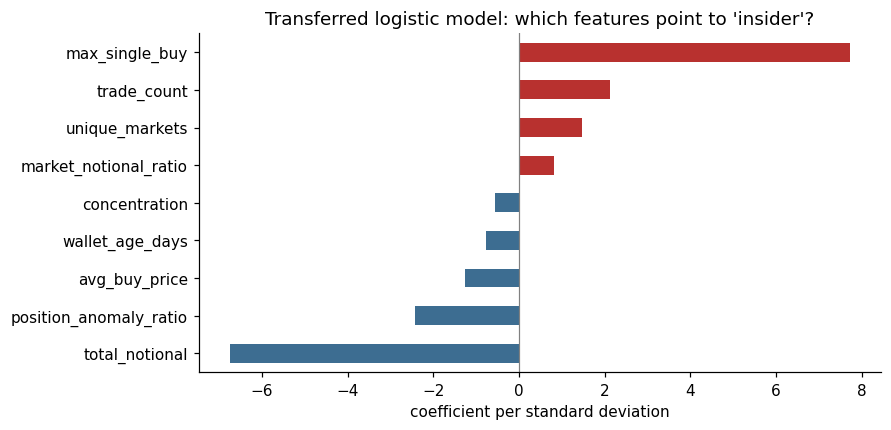

How similar are the rankings? (Spearman correlation between methods on our wallets)

,Demo forest,Biggest spenders,Forest + logs,Forest + logs + size,Insider profile,Ensemble (forest + spend + profile),Logistic regression (trained on course labels)
Demo forest,1.00,0.56,0.86,0.79,0.40,0.70,0.50
Biggest spenders,0.56,1.00,0.40,0.44,0.80,0.90,0.67
Forest + logs,0.86,0.40,1.00,0.89,0.29,0.64,0.46
Forest + logs + size,0.79,0.44,0.89,1.00,0.35,0.70,0.55
Insider profile,0.40,0.80,0.29,0.35,1.00,0.86,0.74
Ensemble (forest + spend + profile),0.70,0.90,0.64,0.70,0.86,1.00,0.79
Logistic regression (trained on course labels),0.50,0.67,0.46,0.55,0.74,0.79,1.00


In [62]:
our_scores = unsupervised_scores(D)
if HAVE_LABELS:
    transfer = LOGIT().fit(Xc, yc)
    coef = pd.Series(transfer[-1].coef_[0], index=Xc.columns).sort_values()
    our_scores["Logistic regression (trained on course labels)"] = transfer.predict_proba(model_matrix(D, DEMO_FEATS + SIZE_FEATS))[:, 1]
    coef.plot.barh(figsize=(8, 4), color=["#3d6d91" if c < 0 else "#b8312f" for c in coef],
                   title="Transferred logistic model: which features point to 'insider'?")
    plt.axvline(0, color="grey", lw=0.8); plt.xlabel("coefficient per standard deviation"); plt.show()

RANKS = pd.DataFrame({m: pd.Series(s, index=D.index).rank(ascending=False, pct=True) for m, s in our_scores.items()})
display(Markdown("How similar are the rankings? (Spearman correlation between methods on our wallets)"))
display(RANKS.corr(method="spearman").round(2))

##### 3.2.5 Do the flagged wallets actually look informed?

We have no labels here, but we have an independent check: settled markets. If a detector finds informed traders, the wallets it ranks highest should **win more often than their buy prices imply** (`skill_z` from Section 2.4) and make money. None of the detectors uses outcomes, so this is a fair test. For each method we compare its top 1% with everyone else.

,wallets flagged,median skill_z (≥5 settled positions),everyone else,share with skill_z ≥ 2,everyone else,median ROI,share profitable
Demo forest,7406,-0.08,-0.18,2.3%,1.1%,+0.1%,50.7%
Biggest spenders,7406,-0.06,-0.17,2.2%,1.1%,+0.3%,57.1%
Forest + logs,7406,-0.13,-0.17,2.2%,1.1%,-0.7%,46.6%
Forest + logs + size,7406,-0.09,-0.17,2.4%,1.1%,+0.1%,51.5%
Insider profile,7406,-0.11,-0.17,1.8%,1.1%,-31.1%,37.1%
Ensemble (forest + spend + profile),7419,-0.09,-0.17,2.5%,1.1%,-0.1%,49.2%
Logistic regression (trained on course labels),7406,-0.08,-0.17,2.3%,1.1%,-3.5%,44.1%


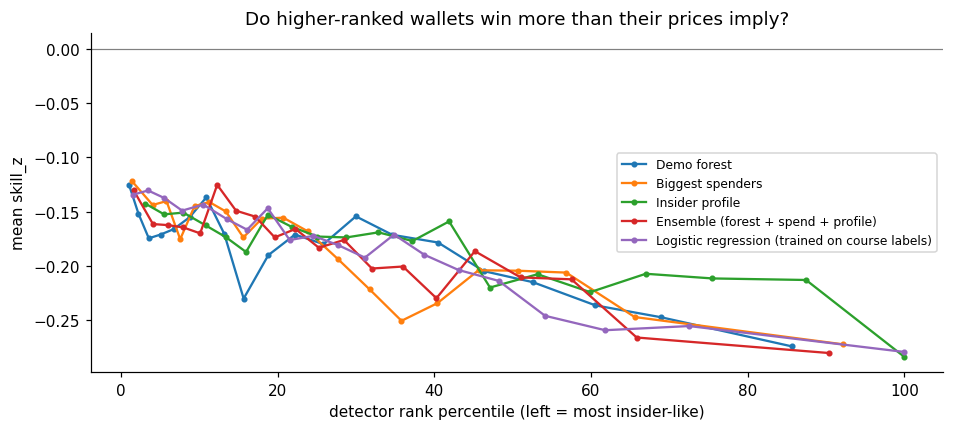

In [ ]:
check = D.join(wallets[["skill_z", "n_resolved_positions", "profit", "roi"]], how="left")
rows = {}
for m in RANKS.columns:
    top = RANKS[m] <= 0.01
    t, rest = check[top], check[~top]
    t5, rest5 = t[t.n_resolved_positions >= 5], rest[rest.n_resolved_positions >= 5]
    rows[m] = {"wallets flagged": int(top.sum()),
               "median skill_z (≥5 settled positions)": t5.skill_z.median(),
               "everyone else": rest5.skill_z.median(),
               "share with skill_z ≥ 2": (t5.skill_z >= 2).mean(),
               "everyone else ": (rest5.skill_z >= 2).mean(),
               "median ROI": t.roi.median(), "share profitable": (t.profit.dropna() > 0).mean()}
validation = pd.DataFrame(rows).T
display(validation.style.format({"wallets flagged": "{:.0f}",
                                 "median skill_z (≥5 settled positions)": "{:+.2f}", "everyone else": "{:+.2f}",
                                 "share with skill_z ≥ 2": "{:.1%}", "everyone else ": "{:.1%}",
                                 "median ROI": "{:+.1%}", "share profitable": "{:.1%}"}, na_rep="–"))

fig, ax = plt.subplots(figsize=(10, 4))
for m in ["Demo forest", "Biggest spenders", "Insider profile", "Ensemble (forest + spend + profile)"] + \
         [c for c in RANKS.columns if c.startswith("Logistic")]:
    s = check.assign(r=RANKS[m])[check.n_resolved_positions >= 5].sort_values("r")
    bins = pd.qcut(s.r, 20, labels=False, duplicates="drop")
    ax.plot(s.groupby(bins).r.max() * 100, s.groupby(bins).skill_z.mean(), marker="o", ms=3, label=m)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="detector rank percentile (left = most insider-like)", ylabel="mean skill_z",
       title="Do higher-ranked wallets win more than their prices imply?")
ax.legend(fontsize=8); plt.show()

A detector that works should show a **falling line** (high `skill_z` on the left) and a top 1% with clearly higher `skill_z` and ROI than everyone else. Agreement between the transferred logistic model (trained on press-confirmed insiders) and this outcome-based check would be the strongest evidence in the report; disagreement is also a finding, and suggests that the confirmed insiders differ from whatever informed trading happens in our 12 weeks.

##### 3.2.6 The suspected-insider rule

A non-bot wallet is a **suspected insider** when two independent kinds of evidence agree:

1. **The detector ranks it in its top 1%.** We use the logistic regression trained on the course's confirmed insiders, because it caught the most of them in 3.2.3. Without the course file we use the unsupervised ensemble (forest + spend + profile), the best method that needs no labels.
2. **Its settled bets won more than their prices imply**: `skill_z ≥ 2` over at least 3 settled positions (Section 2.4).

The detector looks only at *how* a wallet trades; `skill_z` looks only at *whether it was right*. Requiring both removes big spenders who were simply lucky or unlucky, and lucky small gamblers whose trading looks nothing like an insider's.

In [ ]:
DETECTORS = {m: RANKS[m].reindex(wallets.index).fillna(1.0) for m in RANKS.columns}   # rank percentile, 0 = most insider-like
DETECTOR = ("Logistic regression (trained on course labels)" if HAVE_LABELS
            else "Ensemble (forest + spend + profile)")
display(Markdown(f"Detector used for the rule: **{DETECTOR}**"))

Detector used for the rule: **Logistic regression (trained on course labels)**

#### 3.3 Final assignment: bots, suspected insiders, whales and retail

Whale cut-off: at least **$50,049** traded in the 12 weeks.

,wallets,fills,dollars,profit,share_of_wallets,share_of_fills,share_of_dollars
group,,,,,,,
Retail,763239,22462606,"$925,526,020","$-20,951,825",97.91%,33.7%,19.8%
Whale,7893,2026936,"$2,182,566,865","$27,893,580",1.01%,3.0%,46.7%
Bot,8265,42191903,"$1,523,062,681","$8,546,075",1.06%,63.2%,32.6%
Suspected insider,122,54953,"$44,845,395","$16,405,212",0.02%,0.1%,1.0%


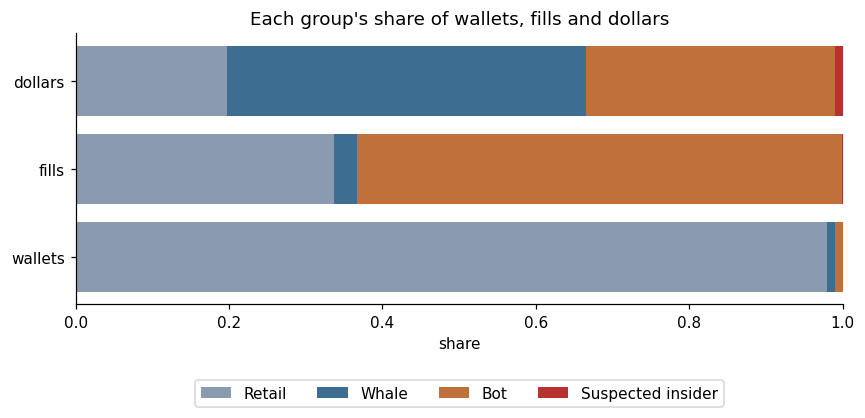

In [ ]:
RULES = dict(bot_markets=500, bot_fills=2000, bot_hours=20, bot_fills_per_day=100,
             detector=DETECTOR, det_top=0.01, ins_z=2.0, ins_positions=3, whale_top=0.01)

def assign_groups(w, r=RULES):
    is_bot = ((w.n_markets >= r["bot_markets"]) | (w.n_fills >= r["bot_fills"])
              | ((w.active_hours_of_day >= r["bot_hours"]) & (w.fills_per_active_day > r["bot_fills_per_day"])))
    is_ins = (~is_bot & (DETECTORS[r["detector"]] <= r["det_top"])
              & (w.skill_z.fillna(-np.inf) >= r["ins_z"]) & (w.n_resolved_positions.fillna(0) >= r["ins_positions"]))
    rest = ~is_bot & ~is_ins
    cut = w.loc[rest, "total_dollars"].quantile(1 - r["whale_top"])
    g = pd.Series("Retail", index=w.index)
    g[rest & (w.total_dollars >= cut)] = "Whale"
    g[is_ins] = "Suspected insider"
    g[is_bot] = "Bot"
    return pd.Categorical(g, categories=GROUPS), cut

wallets["group"], WHALE_CUT = assign_groups(wallets)
summary = wallets.groupby("group", observed=False).agg(wallets=("n_fills", "size"), fills=("n_fills", "sum"),
                                                       dollars=("total_dollars", "sum"), profit=("profit", "sum"))
for c in ["wallets", "fills", "dollars"]:
    summary[f"share_of_{c}"] = summary[c] / summary[c].sum()
display(Markdown(f"Whale cut-off: at least **${WHALE_CUT:,.0f}** traded in the 12 weeks."))
display(summary.style.format({"dollars": "${:,.0f}", "profit": "${:,.0f}", "share_of_wallets": "{:.2%}",
                              "share_of_fills": "{:.1%}", "share_of_dollars": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 3.2))
left = np.zeros(3)
for g in GROUPS:
    vals = summary.loc[g, ["share_of_wallets", "share_of_fills", "share_of_dollars"]].to_numpy(float)
    ax.barh(["wallets", "fills", "dollars"], vals, left=left, color=COLORS[g], label=g)
    left += vals
ax.set(xlim=(0, 1), xlabel="share", title="Each group's share of wallets, fills and dollars")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25)); plt.show()

#### 3.4 How sensitive are the groups to the choices?

The insider rows show what each half of the rule contributes: the detector alone flags many big but ordinary wallets, and the outcome check alone flags lucky wallets that trade nothing like insiders.

In [ ]:
variants = {
    "baseline": {},
    "whale top 0.5%": {"whale_top": 0.005}, "whale top 5%": {"whale_top": 0.05},
    "detector top 0.5%": {"det_top": 0.005}, "detector top 2%": {"det_top": 0.02},
    "skill_z ≥ 1.5": {"ins_z": 1.5}, "skill_z ≥ 3": {"ins_z": 3.0},
    "detector only (no outcome check)": {"ins_z": -np.inf, "ins_positions": 0},
    "outcome check only (no detector)": {"det_top": 1.0},
    "demo forest as the detector": {"detector": "Demo forest"},
    "unsupervised ensemble as the detector": {"detector": "Ensemble (forest + spend + profile)"},
    "bot ≥ 1,000 fills": {"bot_fills": 1000}, "no hour-of-day bot rule": {"bot_hours": 25},
}
rows = []
for name, change in variants.items():
    g, _ = assign_groups(wallets, {**RULES, **change})
    counts = pd.Series(g).value_counts().reindex(GROUPS)
    rows.append({"variant": name, **counts.to_dict()})
display(pd.DataFrame(rows).set_index("variant"))

,Retail,Whale,Bot,Suspected insider
variant,,,,
baseline,763239,7893,8265,122
whale top 0.5%,767276,3856,8265,122
whale top 5%,732575,38557,8265,122
detector top 0.5%,763275,7920,8265,59
detector top 2%,763169,7864,8265,221
skill_z ≥ 1.5,763159,7787,8265,308
skill_z ≥ 3,763531,7713,8265,10
detector only (no outcome check),756441,7641,8265,7172
outcome check only (no detector),761071,7836,8265,2347
